# Error mitigation with Clifford data regression

Noise biases every expectation value a quantum computer returns. **Clifford data
regression** (CDR) learns how: it runs circuits that look like the target but
whose noiseless values we can compute, and fits a map from noisy to noiseless
values. The map then corrects the target's noisy value.

The circuits CDR learns from are the target with most of its non-Clifford gates
swapped for Clifford ones. They hold little magic, which is exactly what mpstab
simulates cheaply, so mpstab gives both their noiseless values and, given a noise
model, their noisy ones.

In this tutorial you will:

1. learn a noise map with `cdr` and use it to mitigate a noisy value;
2. do better with variable-noise CDR, `vncdr`;
3. see how much magic to leave in the training circuits;
4. plug in your own device instead of a simulated noise model.

In [1]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
from qibo import gates

from mpstab import (
    HSMPO,
    CoherentError,
    DepolarizingError,
    NoiseModel,
    ReadoutError,
    cdr,
    noisy_value,
    training_circuits,
    vncdr,
)
from mpstab.models.ansatze import KickedIsing
sys.path.append("../..")  # examples/, home of the plot style
from plotting import COLORS, set_style

set_style()

## The circuit and its noise

Our target is a 12-qubit kicked Ising chain with three steps. Its kicks and
couplings are all non-Clifford, so it holds plenty of magic. We measure the
$Z Z$ correlation between the two central qubits.

The noise model mimics a superconducting device: depolarizing noise after
every gate, ten times stronger on the CNOTs, a residual coherent $ZZ$ coupling
on the CNOTs and asymmetric readout errors.

In [2]:
nqubits = 12
ansatz = KickedIsing(nqubits=nqubits, n_steps=3, theta_h=0.7, theta_z=0.3, theta_j=-1.3)
observable = "I" * 5 + "ZZ" + "I" * 5

noise = (
    NoiseModel()
    .add(DepolarizingError(2e-3), gates.RX)
    .add(DepolarizingError(2e-2), gates.CNOT)
    .add(CoherentError("ZZ", 0.03), gates.CNOT)
    .add(ReadoutError(0.01, 0.03))
)

target = HSMPO(ansatz, progress=False)
exact = target.expectation(observable)
noisy = noisy_value(target, observable, noise, seed=1)

print(f"{target.n_gates} gates, {target.n_magic_gates} of them magic")
print(f"exact  <ZZ> = {exact:+.4f}")
print(f"noisy  <ZZ> = {noisy:+.4f}   (error {abs(noisy - exact):.3f})")

171 gates, 105 of them magic
exact  <ZZ> = +0.6653
noisy  <ZZ> = +0.4399   (error 0.225)


`noisy_value` is a thin wrapper around `HSMPO.noisy_expectation`: it plays the
role of the quantum computer here. The noise pulls the correlation well below its
true value. Let's correct it.

## Training circuits

`training_circuits` samples variants of the target: each non-Clifford gate is
replaced by its nearest Clifford gate with probability `replacement_probability`,
and kept otherwise. The few magic gates left make each training circuit a bit
different, and keep it close to the target.

In [3]:
circuits = training_circuits(ansatz, 5, replacement_probability=0.8, seed=0)
magic = [HSMPO(c, progress=False).n_magic_gates for c in circuits]
print("magic gates in five training circuits:", magic, f"(target: {target.n_magic_gates})")

magic gates in five training circuits: [31, 16, 22, 26, 23] (target: 105)


## CDR: one noisy value per circuit

`cdr` samples the training circuits, computes each one's noiseless and noisy
value with mpstab and fits the line
$\langle O \rangle_{\rm exact} = a\, \langle O \rangle_{\rm noisy} + b$.
It returns a `MitigationNoiseMap`: call it on a noisy value to get the mitigated
one. `n_workers` spreads the training circuits over processes.

In [4]:
start = time.perf_counter()
noise_map = cdr(
    ansatz, observable, noise,
    n_training_circuits=30, replacement_probability=0.8, seed=0, n_workers=4,
)
print(f"trained in {time.perf_counter() - start:.1f} s, fit a = {noise_map.params[0]:.3f}, b = {noise_map.params[1]:+.4f}")

mitigated_cdr = noise_map(noisy)
print(f"CDR    <ZZ> = {mitigated_cdr:+.4f}   (error {abs(mitigated_cdr - exact):.3f})")

trained in 5.9 s, fit a = 1.567, b = -0.0390
CDR    <ZZ> = +0.6501   (error 0.015)


The map keeps its training data, so we can look at what it learned. Each blue
dot is a training circuit; the line is the fitted map. The noisy value of the
target, projected onto the line, lands close to its exact value.

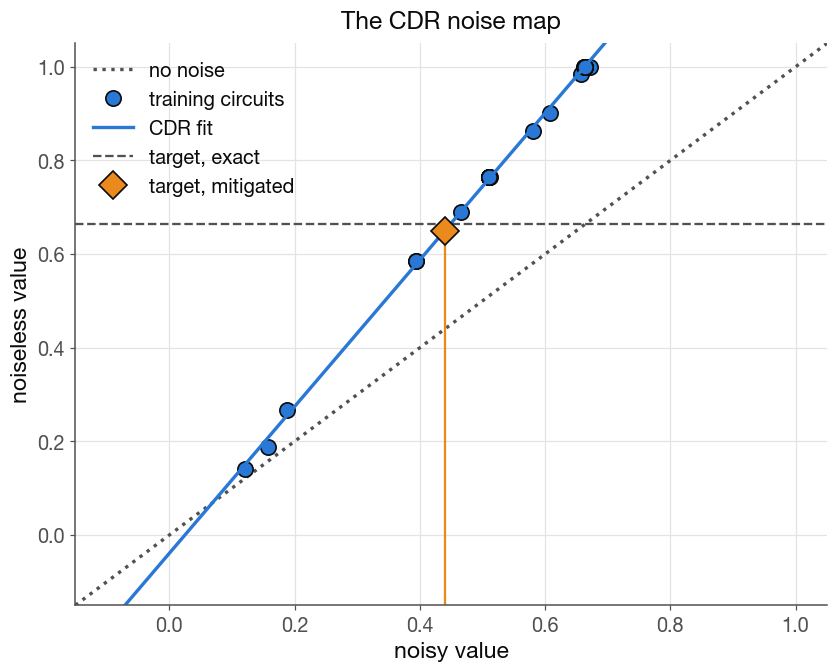

In [5]:
lims = np.array([-0.15, 1.05])
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.plot(lims, lims, ":", color=COLORS["gray"], label="no noise")
ax.plot(noise_map.noisy, noise_map.exact, "o", color=COLORS["blue"], label="training circuits")
ax.plot(lims, noise_map(lims), "-", color=COLORS["blue"], label="CDR fit")
ax.axhline(exact, ls="--", color=COLORS["gray"], lw=1.5, label="target, exact")
ax.plot([noisy, noisy], [lims[0], mitigated_cdr], "-", color=COLORS["orange"], lw=1.5)
ax.plot(noisy, mitigated_cdr, "D", color=COLORS["orange"], ms=13, label="target, mitigated")
ax.set(xlim=lims, ylim=lims, xlabel="noisy value", ylabel="noiseless value", title="The CDR noise map")
ax.legend(loc="upper left")
plt.show()

## Variable-noise CDR

CDR assumes the noise acts on every circuit in the same, linear way. Variable-noise
CDR adds information: it measures each circuit at several noise levels and learns
the noiseless value as a linear combination of them,
$\langle O \rangle_{\rm exact} = \sum_\lambda c_\lambda \langle O \rangle_\lambda$.
It is zero-noise extrapolation whose coefficients are learned rather than assumed.

With a noise model, `amplification="scale"` multiplies every error's strength by
the level; on hardware you would fold the circuit instead (`amplification="fold"`,
or `fold_circuit` yourself).

In [6]:
levels = (1, 2, 3)
start = time.perf_counter()
vn_map = vncdr(
    ansatz, observable, noise, noise_levels=levels,
    n_training_circuits=30, replacement_probability=0.8, seed=0, n_workers=4,
)
print(f"trained in {time.perf_counter() - start:.1f} s, coefficients {np.round(vn_map.params, 3)}")

noisy_levels = [noisy_value(target, observable, noise, level, seed=1) for level in levels]
mitigated_vn = vn_map(noisy_levels)
print(f"vnCDR  <ZZ> = {mitigated_vn:+.4f}   (error {abs(mitigated_vn - exact):.4f})")

trained in 8.2 s, coefficients [ 2.261 -0.755 -0.559]


vnCDR  <ZZ> = +0.6654   (error 0.0001)


Plotting the target's value against the noise level shows what both methods do:
they bring the measured values back to the noiseless limit, with vnCDR landing
almost exactly on it.

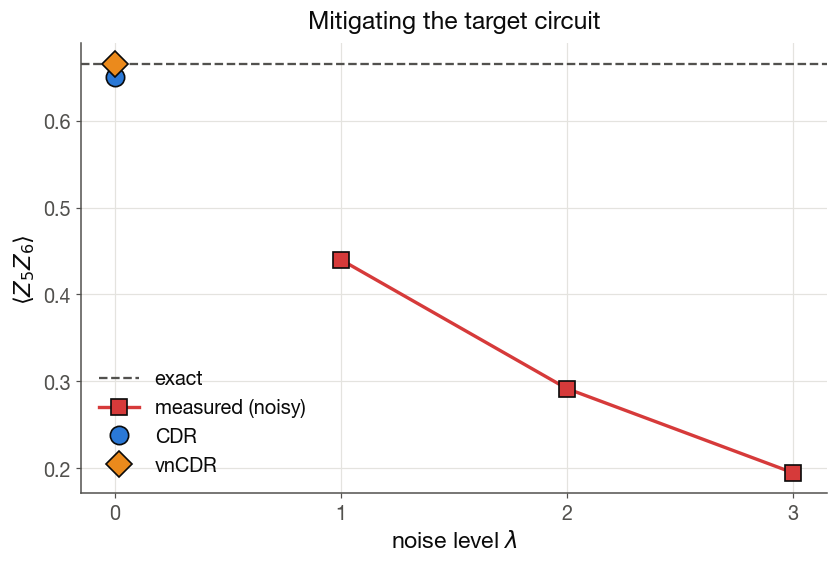

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.axhline(exact, ls="--", color=COLORS["gray"], lw=1.5, label="exact")
ax.plot(levels, noisy_levels, "s-", color=COLORS["red"], label="measured (noisy)")
ax.plot(0, mitigated_cdr, "o", color=COLORS["blue"], ms=12, label="CDR")
ax.plot(0, mitigated_vn, "D", color=COLORS["orange"], ms=12, label="vnCDR")
ax.set(xlabel="noise level $\\lambda$", ylabel="$\\langle Z_5 Z_6 \\rangle$",
       xticks=[0, *levels], title="Mitigating the target circuit")
ax.legend(loc="lower left")
plt.show()

## How much magic to keep

The replacement probability sets how close the training circuits are to the
target. Replacing every gate gives pure Clifford circuits, as in the original
CDR; with the closest replacement those would be thirty copies of one circuit,
so we draw the Clifford angles at random instead. Lower probabilities keep more
magic gates: the training circuits resemble the target more, and cost more to
simulate. Let's compare the mitigated error across these choices.

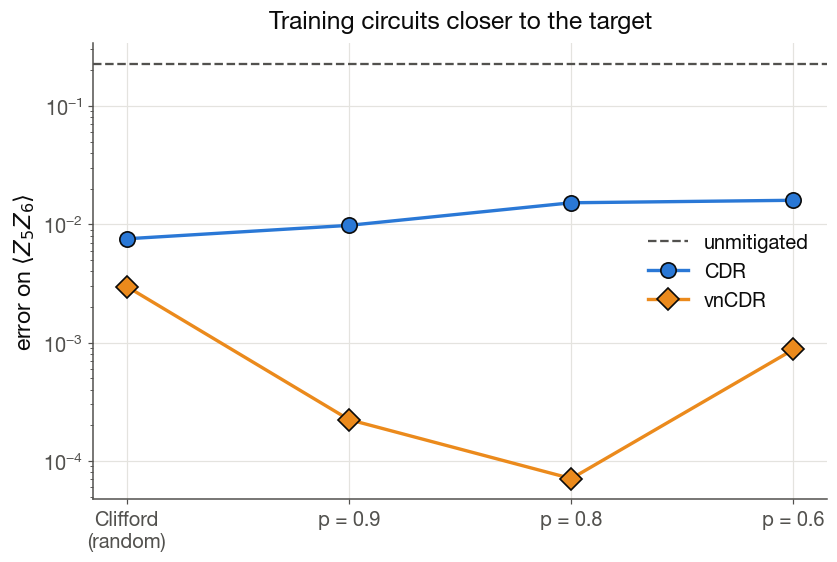

In [8]:
settings = [(1.0, "random"), (0.9, "closest"), (0.8, "closest"), (0.6, "closest")]
errors = {"CDR": [], "vnCDR": []}
for p, method in settings:
    kwargs = dict(n_training_circuits=30, replacement_probability=p,
                  replacement_method=method, seed=0, n_workers=4)
    errors["CDR"].append(abs(cdr(ansatz, observable, noise, **kwargs)(noisy) - exact))
    errors["vnCDR"].append(abs(vncdr(ansatz, observable, noise, levels, **kwargs)(noisy_levels) - exact))

labels = ["Clifford\n(random)", "p = 0.9", "p = 0.8", "p = 0.6"]
x = np.arange(len(settings))
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.axhline(abs(noisy - exact), ls="--", color=COLORS["gray"], lw=1.5, label="unmitigated")
ax.plot(x, errors["CDR"], "o-", color=COLORS["blue"], label="CDR")
ax.plot(x, errors["vnCDR"], "D-", color=COLORS["orange"], label="vnCDR")
ax.set(yscale="log", xticks=x, xticklabels=labels, ylabel="error on $\\langle Z_5 Z_6 \\rangle$",
       title="Training circuits closer to the target")
ax.legend(loc="center right")
plt.show()

The two methods react differently. CDR's error barely moves: a single
straight line is what limits it, not which circuits it learns from. vnCDR gains
more than an order of magnitude when the training circuits keep some magic,
since its learned extrapolation then matches how the target responds to the
noise; with too much magic left (p = 0.6) the training values spread less and the
gain shrinks. These numbers come from one seed and one circuit, so take the
trend, not the digits: a replacement probability around 0.8 to 0.9 is a good
default, and mpstab keeps those training circuits cheap.

## Using your own device

So far the noisy values came from a simulated noise model. On real hardware,
pass a function instead: `cdr` calls it on every training circuit (a qibo
`Circuit`) and expects the measured expectation value back; for `vncdr` it also
receives the noise level. mpstab still computes all the noiseless values.

Below, a stand-in "device" runs the circuit through the same noise model, so the
result matches the one above.

In [9]:
def run_on_device(circuit):
    """Measure <ZZ> on the device. Here: a simulated one."""
    return noisy_value(HSMPO(circuit, progress=False), observable, noise, seed=1)


device_map = cdr(ansatz, observable, run_on_device, n_training_circuits=30,
                 replacement_probability=0.8, seed=0)
print(f"CDR with a device function: {device_map(noisy):+.4f}")

CDR with a device function: +0.6504


## Summary

- `cdr(ansatz, observable, noise)` learns a noise map from low-magic training
  circuits, which mpstab simulates cheaply; call the map on a noisy value.
- `vncdr` adds noise levels and learns a zero-noise extrapolation; it is usually
  far more accurate.
- `replacement_probability` sets how much magic the training circuits keep:
  around 0.8 to 0.9 helps vnCDR most, and mpstab keeps it cheap.
- `noise` can be a `NoiseModel` or your own function running circuits on hardware.

The *Noise* and *Advanced noise* tutorials show how to build richer device noise
models, such as relaxation, crosstalk and idling, which `cdr` and `vncdr` accept
unchanged.